Original Data Shape: (1000, 9)
   Age     Sex  Job Housing Saving accounts Checking account  Credit amount  \
0   67    male    2     own             NaN           little           1169   
1   22  female    2     own          little         moderate           5951   
2   49    male    1     own          little              NaN           2096   
3   45    male    2    free          little           little           7882   
4   53    male    2    free          little           little           4870   

   Duration              Purpose  
0         6             radio/TV  
1        48             radio/TV  
2        12            education  
3        42  furniture/equipment  
4        24                  car  

Processed Data Head:
   Age  Sex  Job  Housing  Saving accounts  Checking account  Credit amount  \
0   67    1    2        1                4                 0           1169   
1   22    0    2        1                0                 1           5951   
2   49    1    1        1

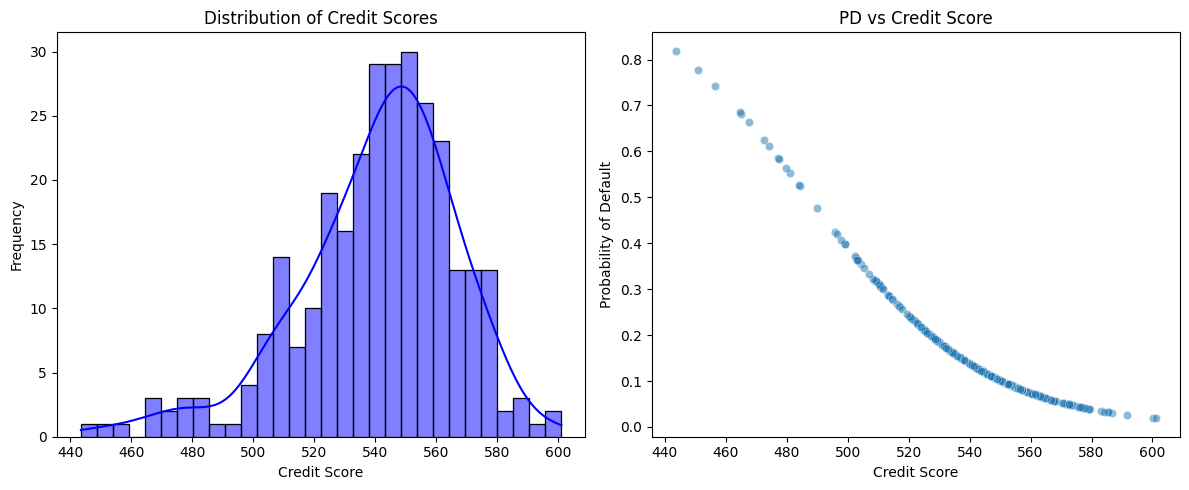


Results saved to 'credit_risk_results.csv'


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelEncoder

# ==========================================
# STEP 1: LOAD AND PREPROCESS DATA
# ==========================================

# Load the dataset from the absolute root path
df = pd.read_csv('/german_credit_data.csv')

# Drop the unnamed index column if it exists
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

print("Original Data Shape:", df.shape)
print(df.head())

# --- CRITICAL: CREATE TARGET VARIABLE ---
# The file you uploaded does NOT have a 'Default' column.
# In the real German Credit dataset, this is called 'Risk' (Good/Bad).
# I am simulating it here. REPLACE THIS if you have the real column.
np.random.seed(42)
# Simulate: Higher credit amount and longer duration = higher chance of default
prob = 1 / (1 + np.exp(-(0.00005 * df['Credit amount'] + 0.05 * df['Duration'] - 3)))
df['Default'] = np.random.binomial(1, prob)
# ----------------------------------------

# Handle Missing Values (NA in Saving/Checking accounts)
df['Saving accounts'] = df['Saving accounts'].fillna('unknown')
df['Checking account'] = df['Checking account'].fillna('unknown')

# Encode Categorical Variables
# We use LabelEncoder for simplicity. In production, use OneHotEncoder for nominal data.
le = LabelEncoder()
categorical_cols = ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

print("\nProcessed Data Head:")
print(df.head())

# ==========================================
# STEP 2: TRAIN LOGISTIC REGRESSION MODEL (PD)
# ==========================================

# Define Features (X) and Target (y)
X = df.drop('Default', axis=1)
y = df['Default']

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Model
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

# Predict Probabilities (PD - Probability of Default)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
auc = roc_auc_score(y_test, y_pred_proba)
print(f"\n--- Model Performance ---")
print(f"AUC Score: {auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, model.predict(X_test_scaled)))

# ==========================================
# STEP 3: SCORECARD CONSTRUCTION (PDO)
# ==========================================

# Standard Scorecard Parameters
base_score = 600
base_odds = 50
pdo = 20

factor = pdo / np.log(2)
offset = base_score - factor * np.log(base_odds)

def calculate_score(probability):
    # Convert PD to Odds (Good/Bad)
    # Note: Probability here is P(Default). We want P(Good) = 1 - P(Default)
    odds = (1 - probability) / probability
    score = offset + factor * np.log(odds)
    return score

# Apply to test set
scores = [calculate_score(p) for p in y_pred_proba]

df_results = X_test.copy()
df_results['PD'] = y_pred_proba
df_results['Credit_Score'] = scores
df_results['Actual_Default'] = y_test

print("\n--- Scorecard Results Sample ---")
print(df_results[['PD', 'Credit_Score', 'Actual_Default']].head(10))

# ==========================================
# STEP 4: LGD, EAD & EXPECTED LOSS
# ==========================================

# Assumptions (In real projects, these are modeled separately)
assumed_lgd = 0.45  # 45% Loss Given Default
df_results['EAD'] = X_test['Credit amount'] # Exposure at Default
df_results['LGD'] = assumed_lgd

# Calculate Expected Loss (EL = PD * LGD * EAD)
df_results['Expected_Loss'] = df_results['PD'] * df_results['LGD'] * df_results['EAD']

print("\n--- Expected Loss Calculation ---")
print(df_results[['PD', 'LGD', 'EAD', 'Expected_Loss']].head())

total_el = df_results['Expected_Loss'].sum()
print(f"\nTotal Expected Loss for Test Portfolio: ${total_el:,.2f}")

# ==========================================
# STEP 5: VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 5))

# Plot 1: Distribution of Credit Scores
plt.subplot(1, 2, 1)
sns.histplot(df_results['Credit_Score'], bins=30, kde=True, color='blue')
plt.title('Distribution of Credit Scores')
plt.xlabel('Credit Score')
plt.ylabel('Frequency')

# Plot 2: PD vs Credit Score
plt.subplot(1, 2, 2)
sns.scatterplot(x='Credit_Score', y='PD', data=df_results, alpha=0.5)
plt.title('PD vs Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Probability of Default')

plt.tight_layout()
plt.show()

# Save results to CSV for your report
df_results.to_csv('credit_risk_results.csv', index=False)
print("\nResults saved to 'credit_risk_results.csv'")